In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
data = pd.read_csv('Data.csv')

In [3]:
data


,Country;Age;Salary;Purchased
0,France;44;72000;No
1,Spain;27;48000;Yes
2,Germany;30;54000;No
3,Spain;38;61000;No
4,Germany;40;;Yes
5,France;35;58000;Yes
6,Spain;;52000;No
7,France;48;79000;Yes
8,Germany;50;83000;No
9,France;37;67000;Yes


In [4]:
dataset = pd.read_csv('Data.csv',sep=';')

In [5]:
dataset

,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,NaN,Yes
5,France,35.0,58000.0,Yes
6,Spain,NaN,52000.0,No
7,France,48.0,79000.0,Yes
8,Germany,50.0,83000.0,No
9,France,37.0,67000.0,Yes


In [6]:
dataset.Age

0     44.0
1     27.0
2     30.0
3     38.0
4     40.0
5     35.0
6      NaN
7     48.0
8     50.0
9     37.0
10    32.0
11    50.0
Name: Age, dtype: float64

In [7]:
dataset['Age']

0     44.0
1     27.0
2     30.0
3     38.0
4     40.0
5     35.0
6      NaN
7     48.0
8     50.0
9     37.0
10    32.0
11    50.0
Name: Age, dtype: float64

In [8]:
dataset[['Age']]

,Age
0,44.0
1,27.0
2,30.0
3,38.0
4,40.0
5,35.0
6,NaN
7,48.0
8,50.0
9,37.0


In [9]:
dataset.iloc[:,2].values

array([ 72000.,  48000.,  54000.,  61000.,     nan,  58000.,  52000.,
        79000.,  83000.,  67000., 150000.,  83000.])

In [10]:
dataset.iloc[:,1:3]

,Age,Salary
0,44.0,72000.0
1,27.0,48000.0
2,30.0,54000.0
3,38.0,61000.0
4,40.0,NaN
5,35.0,58000.0
6,NaN,52000.0
7,48.0,79000.0
8,50.0,83000.0
9,37.0,67000.0


In [11]:
dataset2=dataset.drop_duplicates()

In [12]:
dataset2

,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,NaN,Yes
5,France,35.0,58000.0,Yes
6,Spain,NaN,52000.0,No
7,France,48.0,79000.0,Yes
8,Germany,50.0,83000.0,No
9,France,37.0,67000.0,Yes


In [13]:
dataset2['Country'].unique()

array(['France', 'Spain', 'Germany', 'Test'], dtype=object)

(array([4., 0., 0., 3., 0., 0., 3., 0., 0., 1.]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. ]),
 <BarContainer object of 10 artists>)

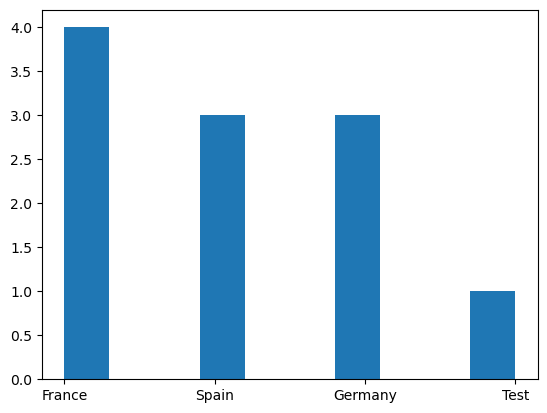

In [14]:
plt.hist(dataset2['Country'])

In [15]:
plt.show()

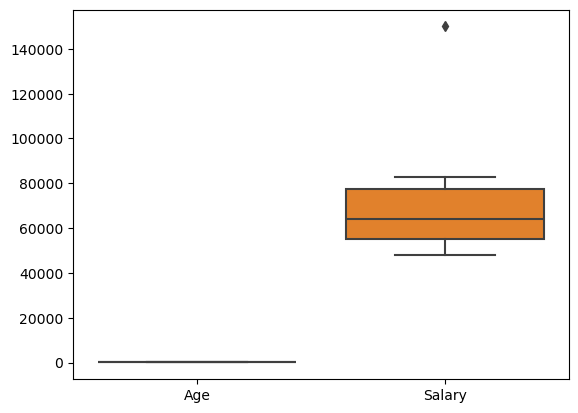

In [16]:
import seaborn as sns
sns.boxplot(data=dataset2,orient="v")
plt.show()

In [17]:
Q3=dataset2.Salary.quantile(0.75)
Q1=dataset2.Salary.quantile(0.25)
limit_sup=Q3+1.5*(Q3-Q1)
limit_sup

110625.0

In [18]:
index= np.where(dataset2['Salary']>limit_sup)
index[0]

array([10], dtype=int64)

In [19]:
dataset3=dataset2.drop(index[0])
dataset3

,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,NaN,Yes
5,France,35.0,58000.0,Yes
6,Spain,NaN,52000.0,No
7,France,48.0,79000.0,Yes
8,Germany,50.0,83000.0,No
9,France,37.0,67000.0,Yes


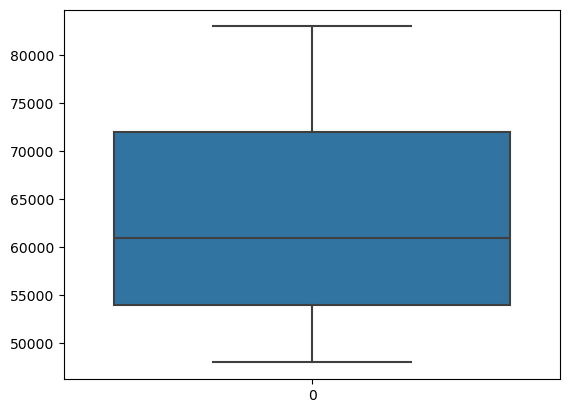

In [20]:
sns.boxplot(data=dataset3['Salary'],orient="v")
plt.show()

In [21]:
dataset4=dataset3.dropna()
dataset4

,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
5,France,35.0,58000.0,Yes
7,France,48.0,79000.0,Yes
8,Germany,50.0,83000.0,No
9,France,37.0,67000.0,Yes


In [22]:
dataset5=dataset3.fillna(dataset3.mean())
dataset5

TypeError: Could not convert ['FranceSpainGermanySpainGermanyFranceSpainFranceGermanyFrance'
 'NoYesNoNoYesYesNoYesNoYes'] to numeric

In [23]:
dataset7=dataset3.fillna({'Salary':int(dataset3['Salary'].mean()),'Age':int(dataset3['Age'].mean())})
dataset7

,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,63777.0,Yes
5,France,35.0,58000.0,Yes
6,Spain,38.0,52000.0,No
7,France,48.0,79000.0,Yes
8,Germany,50.0,83000.0,No
9,France,37.0,67000.0,Yes


In [24]:
x=dataset7.iloc[:,:-1].values
x

array([['France', 44.0, 72000.0],
       ['Spain', 27.0, 48000.0],
       ['Germany', 30.0, 54000.0],
       ['Spain', 38.0, 61000.0],
       ['Germany', 40.0, 63777.0],
       ['France', 35.0, 58000.0],
       ['Spain', 38.0, 52000.0],
       ['France', 48.0, 79000.0],
       ['Germany', 50.0, 83000.0],
       ['France', 37.0, 67000.0]], dtype=object)

In [25]:
x_df=dataset7.iloc[:,:-1]
x_df

,Country,Age,Salary
0,France,44.0,72000.0
1,Spain,27.0,48000.0
2,Germany,30.0,54000.0
3,Spain,38.0,61000.0
4,Germany,40.0,63777.0
5,France,35.0,58000.0
6,Spain,38.0,52000.0
7,France,48.0,79000.0
8,Germany,50.0,83000.0
9,France,37.0,67000.0


In [26]:
y=dataset7.iloc[:,-1].values
y

array(['No', 'Yes', 'No', 'No', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes'],
      dtype=object)

In [27]:
y_df=dataset7.iloc[:,-1]
y_df

0     No
1    Yes
2     No
3     No
4    Yes
5    Yes
6     No
7    Yes
8     No
9    Yes
Name: Purchased, dtype: object

In [28]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
y_le=le.fit_transform(y)
y_le

array([0, 1, 0, 0, 1, 1, 0, 1, 0, 1])

In [29]:
X_dm=pd.get_dummies(x_df, drop_first=True,dtype=int)
X_dm

,Age,Salary,Country_Germany,Country_Spain
0,44.0,72000.0,0,0
1,27.0,48000.0,0,1
2,30.0,54000.0,1,0
3,38.0,61000.0,0,1
4,40.0,63777.0,1,0
5,35.0,58000.0,0,0
6,38.0,52000.0,0,1
7,48.0,79000.0,0,0
8,50.0,83000.0,1,0
9,37.0,67000.0,0,0


In [30]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(X_dm,y_le,test_size=0.2,random_state=1)

In [31]:

X_train, X_test, y_train, y_test

(    Age   Salary  Country_Germany  Country_Spain
 6  38.0  52000.0                0              1
 4  40.0  63777.0                1              0
 0  44.0  72000.0                0              0
 3  38.0  61000.0                0              1
 1  27.0  48000.0                0              1
 7  48.0  79000.0                0              0
 8  50.0  83000.0                1              0
 5  35.0  58000.0                0              0,
     Age   Salary  Country_Germany  Country_Spain
 2  30.0  54000.0                1              0
 9  37.0  67000.0                0              0,
 array([0, 1, 0, 0, 1, 1, 0, 1]),
 array([0, 1]))

In [32]:
x_df.describe().round(2)

,Age,Salary
count,10.00,10.0
mean,38.70,63777.7
std,7.26,11564.1
min,27.00,48000.0
25%,35.50,55000.0
50%,38.00,62388.5
75%,43.00,70750.0
max,50.00,83000.0


<function matplotlib.pyplot.show(close=None, block=None)>

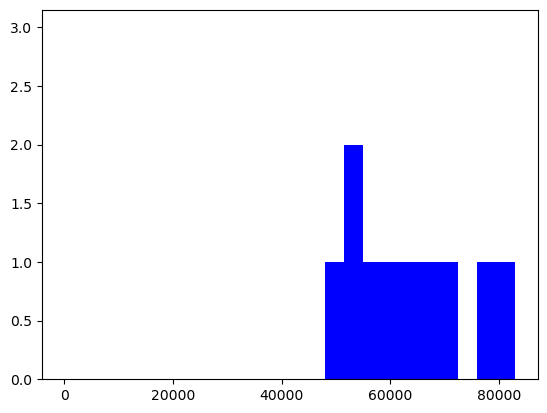

In [33]:
plt.hist(x_df.Age,color='red')
plt.hist(x_df.Salary,color='blue')
plt.show

In [34]:
from sklearn.preprocessing import MinMaxScaler
norm=MinMaxScaler().fit(X_train)
X_train_norm=norm.transform(X_train)
X_test_norm=norm.transform(X_test)
X_train_norm

array([[0.47826087, 0.11428571, 0.        , 1.        ],
       [0.56521739, 0.45077143, 1.        , 0.        ],
       [0.73913043, 0.68571429, 0.        , 0.        ],
       [0.47826087, 0.37142857, 0.        , 1.        ],
       [0.        , 0.        , 0.        , 1.        ],
       [0.91304348, 0.88571429, 0.        , 0.        ],
       [1.        , 1.        , 1.        , 0.        ],
       [0.34782609, 0.28571429, 0.        , 0.        ]])

In [35]:
X_test_norm

array([[0.13043478, 0.17142857, 1.        , 0.        ],
       [0.43478261, 0.54285714, 0.        , 0.        ]])

In [36]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train[['Salary','Age']]=sc.fit_transform(X_train[['Salary','Age']])
X_test[['Salary','Age']]=sc.transform(X_test[['Salary','Age']])

In [37]:
X_train

,Age,Salary,Country_Germany,Country_Spain
6,-0.289430,-1.078117,0,1
4,0.000000,-0.070190,1,0
0,0.578860,0.633570,0,0
3,-0.289430,-0.307858,0,1
1,-1.881294,-1.420454,0,1
7,1.157719,1.232661,0,0
8,1.447149,1.574998,1,0
5,-0.723575,-0.564611,0,0


In [38]:
X_test

,Age,Salary,Country_Germany,Country_Spain
2,-1.447149,-0.906948,1,0
9,-0.434145,0.205649,0,0
